We've come a long way: I'd summarize what we've covered, but...It was getting long.

Here's a secret: This wasn't about convolution, signal processing, neural nets, or even vowels. We'll need all of it where we're going next—but the point is buried beneath it all.

Let's start by considering the "convolution" in CNN.

TODO
- Convolution for moving average; edge detection (downsampling)—concept
- Matrix representation
- Represented by rank 1 matrix; search for redundancy, reveal each row is generated by a shift
- So, convolution is represented by a matrix defined in terms of a polynomial of $ S $, or $ C = \sum_{i} a_{i}S^{i} $, where $ S $ is the shift matrix.
- $ C $ and $ S $ commute; so convolution is **shift equivariant**.
- That means $ C $ and $ S $ share eigenvectors. But the eigenvectors of $ S $ must satisfy $ Sv = \lambda v $; in other words, we need eigenvectors that, when shifted, are equal to a scalar multiple of themselves.
- Pure complex sinusoids—like those composing the basis of our inverse DFT matrix—satisfy this constraint: Multiplying by $ \lambda $ corresponds to multipling a complex exponential by a phase factor. Geometrically, this is the continuous analog to shifting the components of the vector by $ S $; the components don't scale, but simply move by $ \phi $.
- Complex exponentials are the _only_ functions that satisfy this constraint (proof?). So the eigenvectors of $ S $ must be precisely the complex exponentials of our inverse DFT matrix.
- That means we can write $ MSM^{-1} = \Lambda $, concluding that our DFT matrix diagonalizes $ S $.
- But that means $ M $ diagonalizes $ C $—and _all_ circulant matrices.
- This happens precisely because $ C $ and $ S $ commute and share eigenvectors.
- Also: The roots of the polynomial defining $ C $ correspond to the roots of unity defining the columns of the inverse DFT we derived earlier.
- If we plot them, inscribe a polygon, and connect the vertices...We generate a Cayley graph.
- The Cayley graph represents something more general than the "signals" we started with.
- The Fourier basis, then, is _forced_ to be sinusoidal; shift equivariance is forced by commutativity; and the emergence of the Cayley graph reveal that this is due to the relationship between the commutativity of $ C $, circulant matrices that represent the _group action_ of circular shifts, with $ S $, the _generator_ of those actions.
- This raises a natural question: Can we parameterize the underlying group and achieve similar equivariance under different group actions?
- Yes: The simplest example is extending the result to infinite, but still mutually commuting, matrices. This recovers the Fourier transform and z-Transform.
- The next step: Swap $ \textbf{Z} $ for the symmetry group. Now, matrices representing the group action do _not_ commute—but we can generalize our approach to work in terms of invariant subspaces and block diagonalization.
- This is the road to geometric deep learning, and we'll see how to use it to learn over graphs, next.

f0_ss: 174
f1_ss: 663
f2_ss: 2012.0
f3_ss: 2659.0
f4_ss: 3691.0


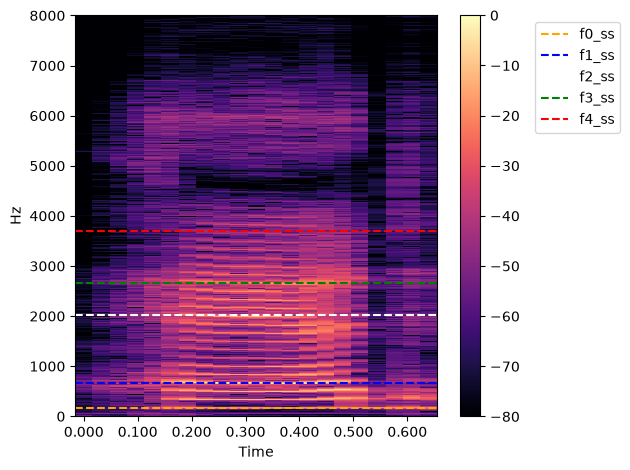

In [224]:
D = lb.stft(audio)  # STFT of y
S_db = lb.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure()
lb.display.specshow(S_db, sr=sr, x_axis="time", y_axis="hz")

cols = [c for c in df.columns if c.endswith(r"ss") and c!= 'filename']
colors = ['red', 'green', 'white', 'blue', 'orange']
for c in cols:
    val = df[c].iloc[0]
    print(f'{c}: {val}')
    plt.axhline(y=val, color=colors.pop(), linestyle='--', label=c)

plt.legend(bbox_to_anchor=(1.25, 1), loc='upper left')
plt.colorbar()
plt.tight_layout()
plt.show()

Not great on the eyes, but it's a good gut check.

```
# in hz
f1_ss: 663
f0_ss: 174
f2_ss: 2012.0
f3_ss: 2659.0
f4_ss: 3691.0
```